## TriKinetics DAM (Drosophila Activity Monitor) Data Pipeline from 9/10 and 9/11

#### Note: The lights were NOT turned back on at 10:00 AM

In [1]:
import csv, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [2]:
# ---------------- SETTINGS ----------------
FILENAME  = 'DAM Monitor 1 Sep10_Sep11_Sep12.txt'
START     = '2026-09-10 16:28'   # first real multibeam reading
DATA_TYPE = 'MT'                 # MT = moves. (CT = counts)
BIN       = '30min'
SLEEP_MIN = 5                    # minutes of no movement = sleep
EXCLUDE   = []                   # tubes to leave out, e.g. DEAD/STUCK
LABELS    = None                 # 32 labels in tube order, e.g. ['IGLoOrRF', ...]

In [3]:
# ---------------- LOAD ----------------
TUBES = [f'tube_{i}' for i in range(1, 33)]
COLS = ['index','date','time','status','extra','monitor','tube_row',
        'dtype','unused','light'] + TUBES            # 10 base cols + 32 tubes

raw = pd.read_csv(FILENAME, sep='\t', header=None, names=COLS, quoting=csv.QUOTE_NONE)
raw['datetime'] = pd.to_datetime(raw['date'] + ' ' + raw['time'], format='%d %b %y %H:%M:%S')
raw['datetime'] = raw['datetime'].dt.floor('min')
print(raw['dtype'].value_counts())

dtype
MT     5408
CT     5408
D12    5408
D34    5408
L12    5408
L34    5408
Rt     5408
Pn     5408
Ct     2810
Name: count, dtype: int64


In [4]:
d = raw[(raw['dtype'] == DATA_TYPE) & (raw['datetime'] >= START)]
d = d.sort_values('datetime', kind='stable').drop_duplicates('datetime').set_index('datetime')
moves = d[TUBES].apply(pd.to_numeric, errors='coerce')
moves = moves.mask(moves == 65535)
full = pd.date_range(moves.index.min(), moves.index.max(), freq='1min')
moves = moves.reindex(full)
light_min = d['light'].reindex(full).ffill()
print(f'{moves.shape[0]} minutes x {moves.shape[1]} tubes')

5564 minutes x 32 tubes


In [5]:
# ---------------- QC ----------------
gaps = moves.isna().all(axis=1)
g = (gaps != gaps.shift()).cumsum()
for _, s in gaps.groupby(g):
    if s.iloc[0]:
        print(f'GAP: {s.index[0]} -> {s.index[-1]} ({len(s)} min)')

qc = pd.DataFrame({'total_moves': moves.sum(),
                   'last_6h': moves.iloc[-360:].sum()})
qc['flag'] = ''
qc.loc[qc['last_6h'] == 0, 'flag'] += 'no movement last 6h '
qc.loc[qc['total_moves'] < 0.25 * qc['total_moves'].median(), 'flag'] += 'very low total '
print('\nTubes to check by eye:')
print(qc[qc['flag'] != ''])

moves_ok = moves.drop(columns=EXCLUDE)

GAP: 2026-09-11 16:38:00 -> 2026-09-11 17:44:00 (67 min)
GAP: 2026-09-12 18:18:00 -> 2026-09-12 19:46:00 (89 min)

Tubes to check by eye:
         total_moves  last_6h                                 flag
tube_15      19290.0      0.0                 no movement last 6h 
tube_17      21840.0      0.0                 no movement last 6h 
tube_32       2206.0      0.0  no movement last 6h very low total 


In [6]:
# ---------------- LABELS ----------------
info = None
if LABELS is not None:
    assert len(LABELS) == 32, f'need 32 labels, got {len(LABELS)}'
    pat = re.compile(r'^(Control\d?|TGHi|TGMed|TGLo|IGHi|IGMed|IGLo)(OrR|YW)([MF])$', re.I)
    rows = []
    for t, lab in zip(TUBES, LABELS):
        m = pat.match(lab); assert m, f'label not recognised: {lab}'
        rows.append(dict(tube=t, label=lab, treatment=m[1], strain=m[2], sex=m[3]))
    info = pd.DataFrame(rows).set_index('tube')
    info['treatment_pooled'] = info['treatment'].str.replace(r'^Control\d$', 'Control', regex=True)


In [7]:
# ---------------- PLOTS ----------------
binned = moves_ok.resample(BIN).sum(min_count=1)

def shade_dark(ax):
    dark = (light_min == 0)
    gr = (dark != dark.shift()).cumsum()
    for _, s in dark.groupby(gr):
        if s.iloc[0]:
            ax.axvspan(s.index[0], s.index[-1], color='0.85', zorder=0)

#### Population curve (A): the average fly across time. The grey band is when the lights were off, taken from the light sensor.

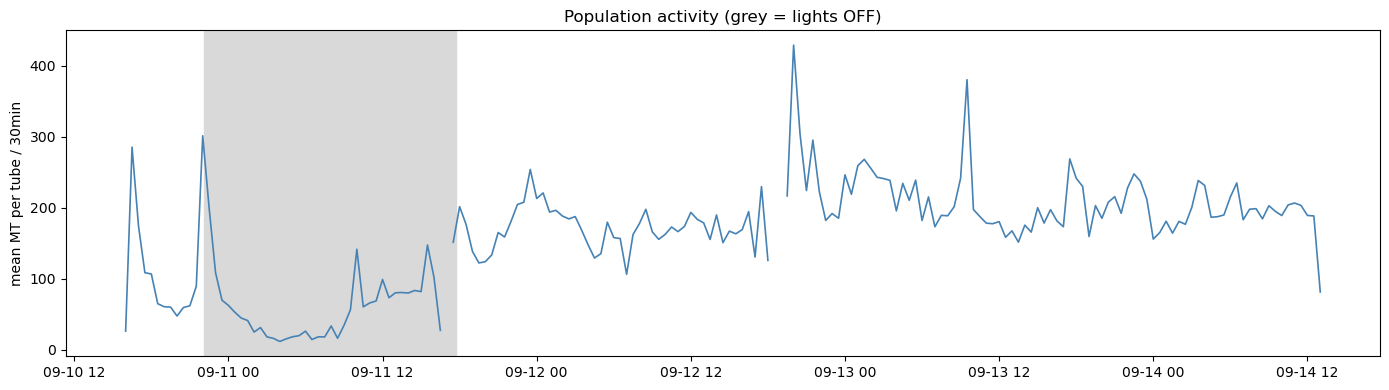

In [8]:
# A. population activity
fig, ax = plt.subplots(figsize=(14, 4))
shade_dark(ax)
ax.plot(binned.index, binned.mean(axis=1), lw=1.2, color='steelblue')
ax.set_ylabel(f'mean {DATA_TYPE} per tube / {BIN}')
ax.set_title('Population activity (grey = lights OFF)')
fig.tight_layout(); fig.savefig('A_population_activity.png', dpi=200); plt.show()

#### Heatmap (B): rows are tubes, columns are time, and brighter means more movement. It's good for spotting a tube that goes dark (dead or stuck) or a synchronized behavior across flies.

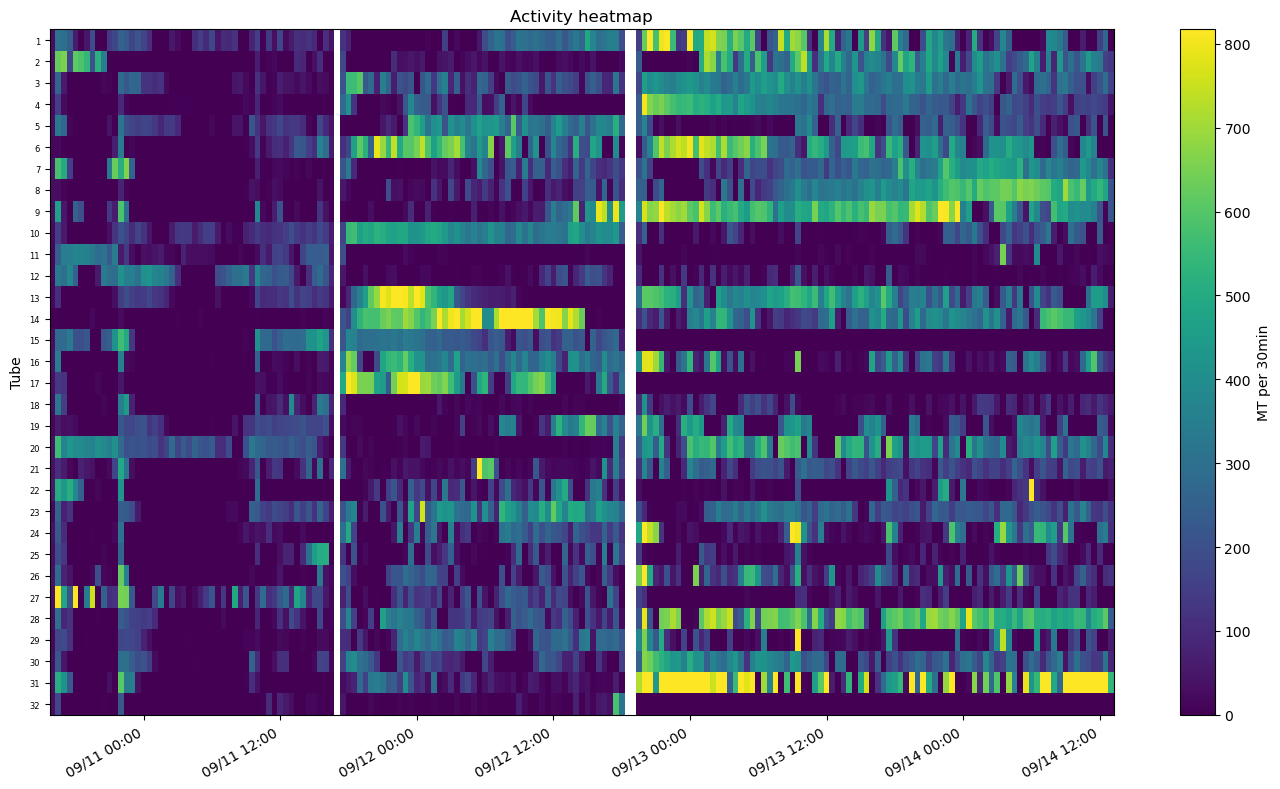

In [9]:
# B. heatmap
fig, ax = plt.subplots(figsize=(14, 8))
x = mdates.date2num(binned.index)
im = ax.pcolormesh(x, np.arange(1, binned.shape[1] + 1), binned.T.values,
                   cmap='viridis', shading='nearest',
                   vmax=np.nanpercentile(binned.values, 99))
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d %H:%M'))
ax.set_yticks(np.arange(1, binned.shape[1] + 1))
ax.set_yticklabels([c.replace('tube_', '') for c in binned.columns], fontsize=6)
ax.invert_yaxis(); ax.set_ylabel('Tube'); ax.set_title('Activity heatmap')
fig.colorbar(im, label=f'{DATA_TYPE} per {BIN}')
fig.autofmt_xdate(); fig.tight_layout(); fig.savefig('B_heatmap.png', dpi=200); plt.show()

#### Mini plots (C): one per tube, so we can check any individual fly. Flagged tubes have red titles.

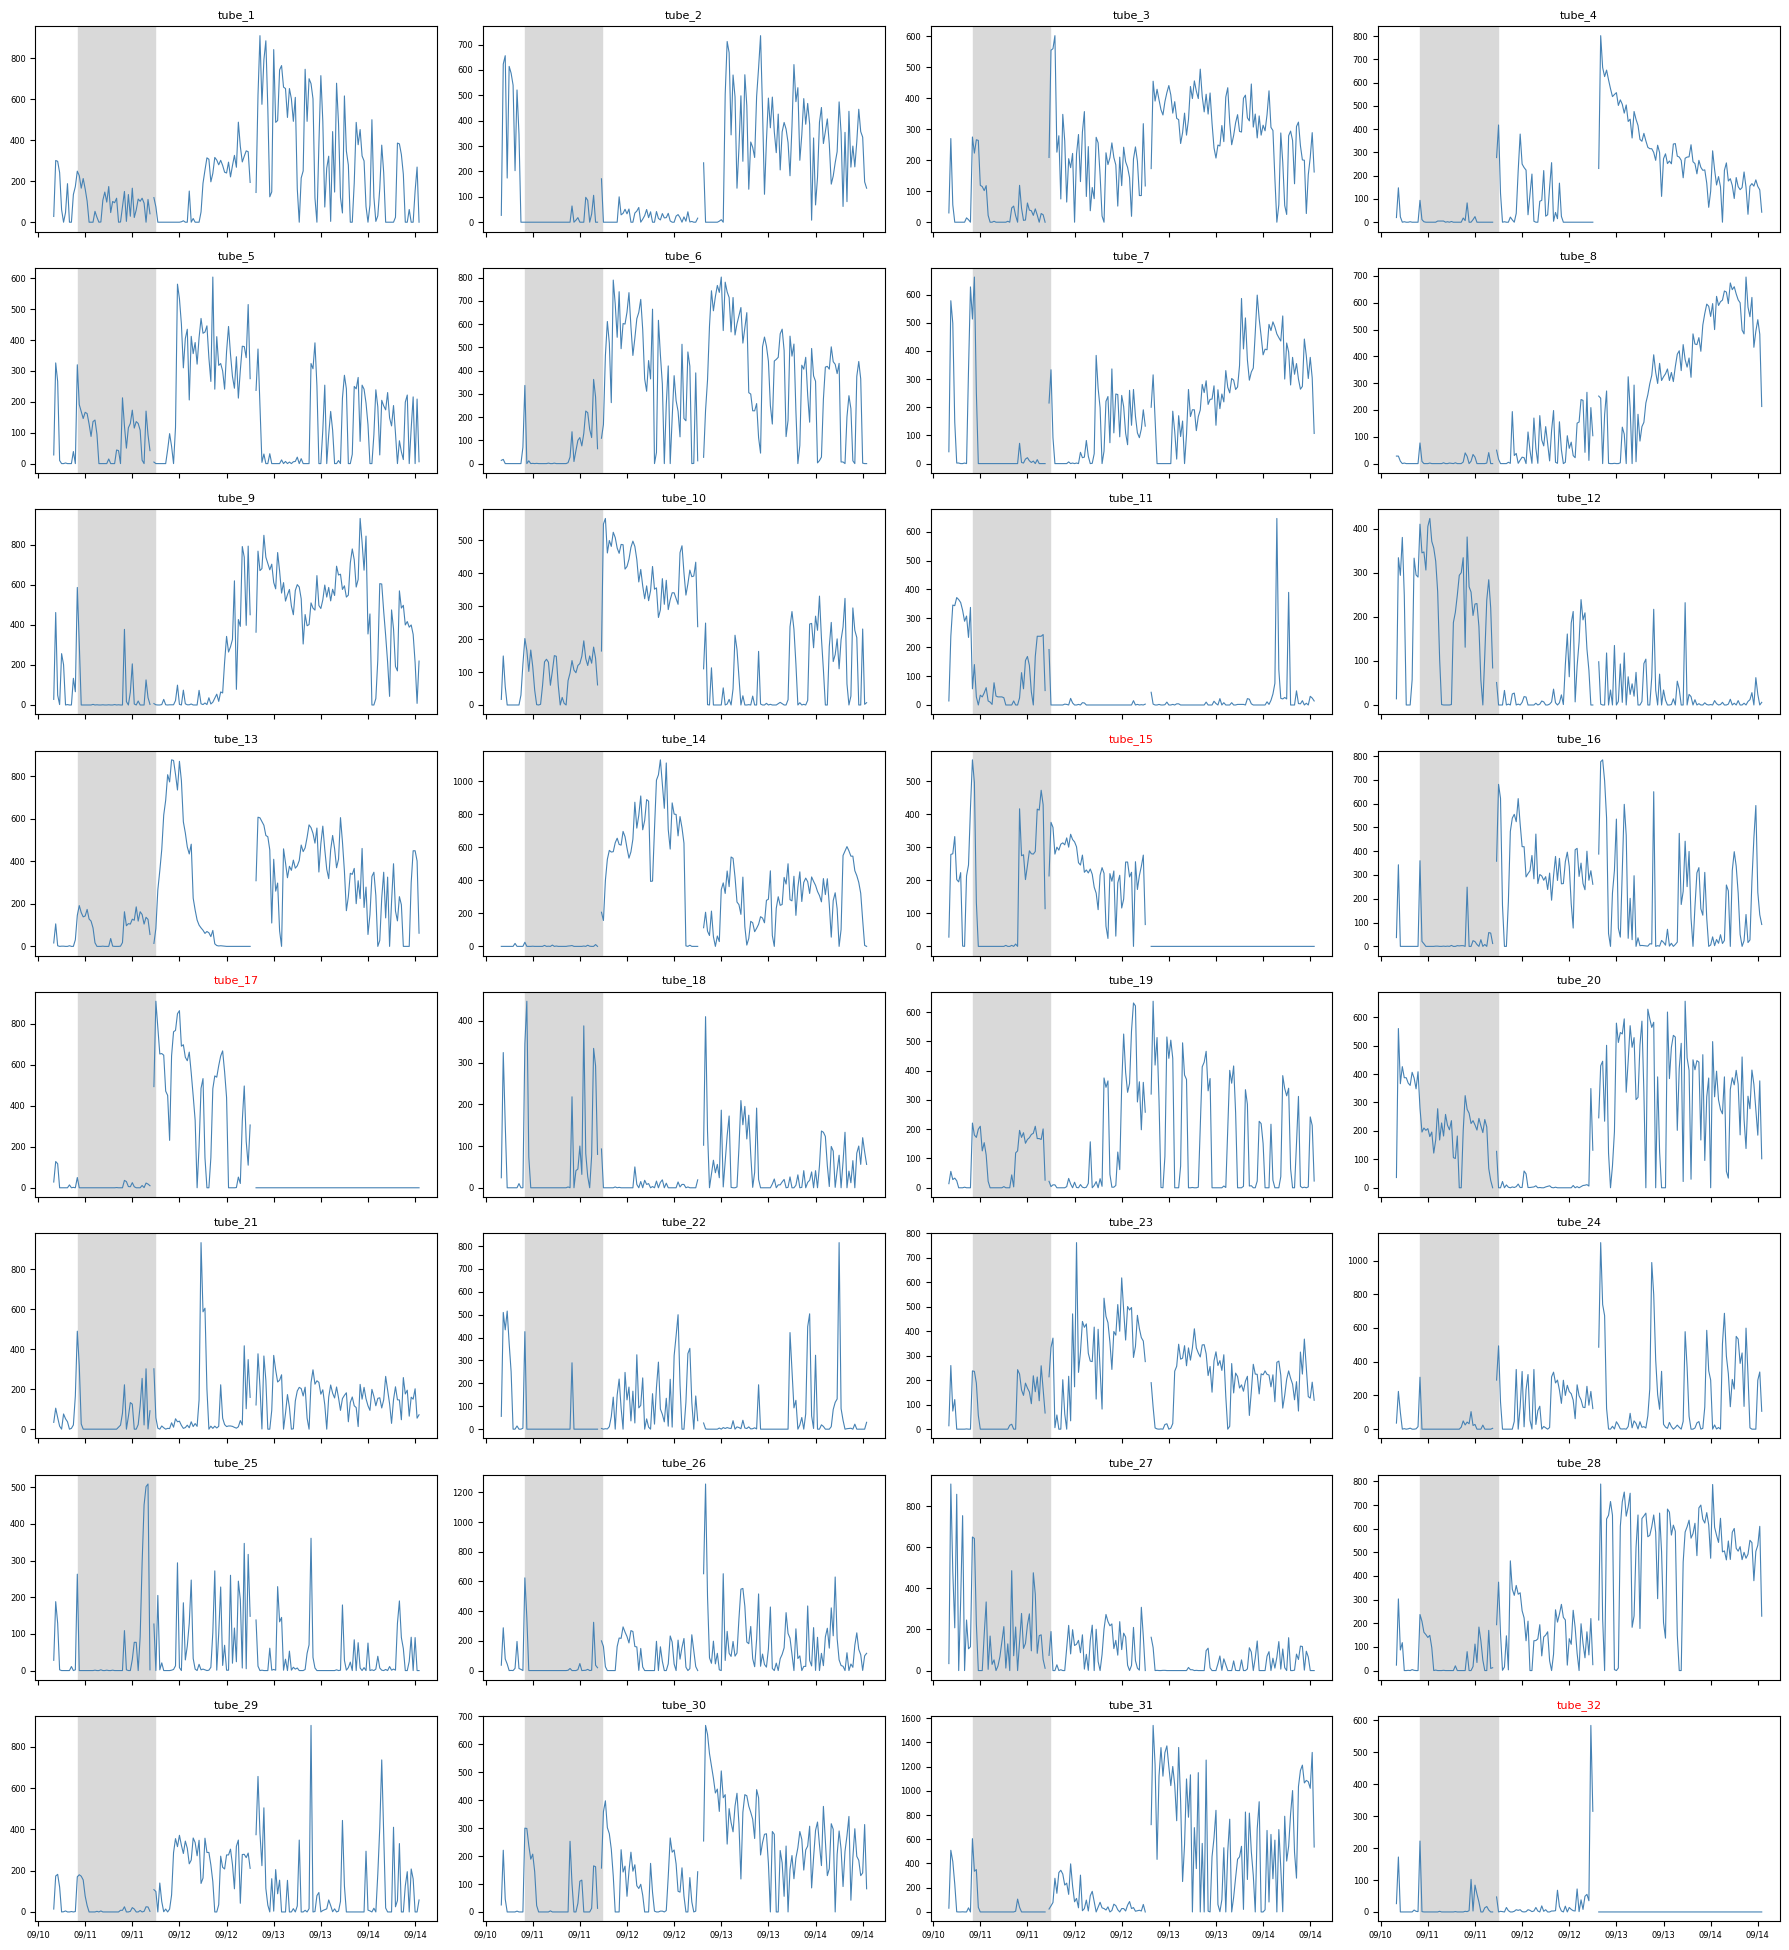

In [10]:
# C. one mini-plot per tube (red title = flagged)
fig, axes = plt.subplots(8, 4, figsize=(18, 20), sharex=True)
for ax, t in zip(axes.flat, TUBES):
    shade_dark(ax)
    if t in binned.columns:
        ax.plot(binned.index, binned[t], lw=0.8, color='steelblue')
    else:
        ax.text(0.5, 0.5, 'excluded', ha='center', va='center', transform=ax.transAxes)
    title = t if info is None else f'{t}\n{info.loc[t, "label"]}'
    ax.set_title(title, fontsize=8, color='red' if qc.loc[t, 'flag'] else 'black')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d'))
    ax.tick_params(labelsize=6)
fig.tight_layout(rect=[0, 0, 1, 0.98]); fig.savefig('C_all_tubes.png', dpi=150); plt.show()

#### Sleep (D): minutes asleep per hour, averaged across flies.

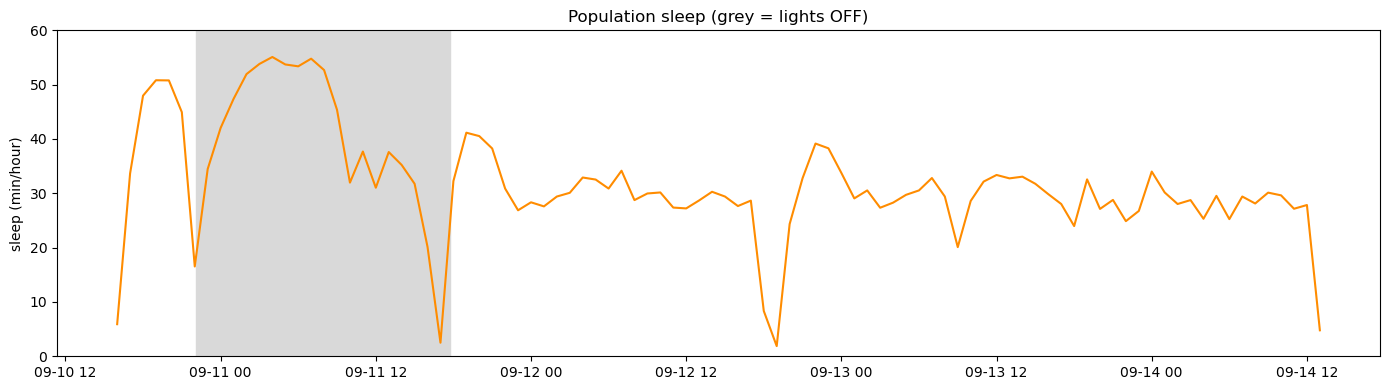

In [11]:
# ---------------- SLEEP ----------------
def sleep_mask(col):
    z = (col == 0)
    gr = (z != z.shift()).cumsum()
    return z & (z.groupby(gr).transform('size') >= SLEEP_MIN)

sleep = moves_ok.apply(sleep_mask).astype(float).where(moves_ok.notna())
sleep_hr = sleep.resample('1h').sum(min_count=1)

fig, ax = plt.subplots(figsize=(14, 4))
shade_dark(ax)
ax.plot(sleep_hr.index, sleep_hr.mean(axis=1), color='darkorange')
ax.set_ylim(0, 60); ax.set_ylabel('sleep (min/hour)')
ax.set_title('Population sleep (grey = lights OFF)')
fig.tight_layout(); fig.savefig('D_sleep.png', dpi=200); plt.show()

In [12]:
# ---------------- SUMMARY ----------------
summary = pd.DataFrame({'total_moves': moves_ok.sum(),
                        'mean_per_min': moves_ok.mean(),
                        'sleep_min_per_h': sleep.mean() * 60})
if info is not None:
    summary = info.join(summary, how='right')
    print(summary.groupby(['treatment_pooled', 'strain', 'sex'])
                 [['total_moves', 'sleep_min_per_h']].agg(['count', 'mean', 'sem']).round(1))
print(summary.round(2))
summary.to_csv('per_tube_summary.csv')

         total_moves  mean_per_min  sleep_min_per_h
tube_1       39612.0          7.32            24.92
tube_2       31706.0          5.86            33.66
tube_3       38201.0          7.06            17.77
tube_4       29148.0          5.39            27.48
tube_5       26872.0          4.97            30.11
tube_6       53886.0          9.96            21.49
tube_7       32282.0          5.97            29.70
tube_8       34678.0          6.41            29.61
tube_9       52460.0          9.70            26.87
tube_10      31007.0          5.73            24.45
tube_11       8043.0          1.49            48.12
tube_12      14499.0          2.68            41.19
tube_13      43809.0          8.10            20.27
tube_14      53556.0          9.90            24.39
tube_15      19290.0          3.57            38.21
tube_16      32843.0          6.07            31.38
tube_17      21840.0          4.04            46.14
tube_18       8014.0          1.48            45.33
tube_19     